In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch
from typing import Optional, Tuple
from dualwcfm import (
    Strategy,
    BidirectionalStrategy,
    Trainer,
    ImplicitCFMLoss,
    ConditionalFlowMatching,
    TrainingConfig,
    FeedForwardConfig,
    Visualizer,
    Visualizer3D,
    VisualizerImage,
    VisualizeConfig,
)
from dualwcfm.distributions import (
    CouplingDistribution,
    RotatedShapeCoupling,
    Simple2DGaussianDistribution,
    RotatedDistribution,
    MoonDistribution,
    SphereDistribution,
    MarginalDistribution
)
from dualwcfm.models.unet import UNetModel
from dualwcfm.distributions.coupling import FixedSizeCouplingDistribution, FunctionalCouplingDistribution

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class unet_wrapper(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, t, x=None, inp3=None, *args, **kwargs):
        if inp3 is not None and x is not None:
            return self.model(t, torch.cat([x, inp3], dim=1))
        if x is not None:
            return self.model(t, x)
        else:
            return self.model(t, torch.zeros_like(t))

class torch_wrapper(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, inp1, inp2=None, inp3=None, *args, **kwargs):
        if inp3 is not None and inp2 is not None:
            return self.model(torch.cat([inp2, inp3, inp1], dim=1))
        if inp2 is not None:
            return self.model(torch.cat([inp2, inp1], dim=1))
        else:
            return self.model(inp1)

c:\Users\Antoine\AppData\Local\Programs\Python\Python39\lib\site-packages\cupy\_environment.py:216: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [12]:
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import numpy as np

class ImageSampler:
    """Helper to turn a DataLoader into an infinite sampler."""

    def __init__(self, dataset, batch_size, device):
        self.loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0, drop_last=True)
        self.iterator = iter(self.loader)
        self.device = device

    def get_batch(self, n):
        try:
            batch, _ = next(self.iterator)
        except StopIteration:
            self.iterator = iter(self.loader)
            batch, _ = next(self.iterator)
        return batch[:n].to(self.device)

class FlipCoupling(CouplingDistribution):

    def __init__(self, dataset, batch_size=32, device: Optional[torch.device] = None, perturbation_fn=None):
        self.device = device if device is not None else torch.device("cpu")
        self.sampler = ImageSampler(dataset, batch_size, self.device)
        self.perturbation_fn = perturbation_fn

    def coupling_sample(self, n: int) -> tuple[torch.Tensor, torch.Tensor]:
        x = self.sampler.get_batch(n)
        y = torch.flip(x, dims=[2])
        if self.perturbation_fn is not None:
            x, y = self.perturbation_fn(x, y)
        return x, y

    def sample(self, n: int) -> torch.Tensor:
        raise NotImplementedError

    def sample_init(self, n: int) -> torch.Tensor:
        if self.perturbation_fn is not None:
            x, _ = self.perturbation_fn(self.sampler.get_batch(n), None)
            return x
        return self.sampler.get_batch(n)

    def sample_target(self, n: int) -> torch.Tensor:
        if self.perturbation_fn is not None:
            _, y = self.perturbation_fn(None, self.sampler.get_batch(n))
            return y
        return torch.flip(self.sampler.get_batch(n), dims=[2])


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_image = False

if use_image:
    batch_size = 128
    tf = T.Compose([T.Resize(32), T.ToTensor(), T.Normalize((0.5,), (0.5,))])

    # ds_mnist = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=tf)
    # ds_fashion = torchvision.datasets.FashionMNIST(root="./data", train=True, download=True, transform=tf)

    # print(f"MNIST size: {len(ds_mnist)}, FashionMNIST size: {len(ds_fashion)}")

    # subset_size = 10000

    # # 3. Create random indices and wrap in a Subset
    # mnist_indices = np.random.choice(len(ds_mnist), subset_size, replace=False)
    # fashion_indices = np.random.choice(len(ds_fashion), subset_size, replace=False)

    # ds_mnist = Subset(ds_mnist, mnist_indices)
    # ds_fashion = Subset(ds_fashion, fashion_indices)

    def small_rotation(x, y):
        # Apply a rotation transform to the images in x and y
        angle = 10  # degrees
        rotation = T.RandomRotation((angle, angle), fill=(-1,))
        if y is not None:
            y_rotated = rotation(y)
            return x, y_rotated
        else:
            return x, y

    # Load mnist and split it in half
    ds_mnist_full = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=tf)

    mnist_half_size = len(ds_mnist_full) // 2
    ds1 = Subset(ds_mnist_full, list(range(mnist_half_size)))
    ds2 = Subset(ds_mnist_full, list(range(mnist_half_size, len(ds_mnist_full))))

    print(f"MNIST size: {len(ds1)}, MNIST size: {len(ds2)}")

    coupling = FlipCoupling(dataset=ds1, batch_size=batch_size, device=device)
    new_coupling_dist = FlipCoupling(dataset=ds2, batch_size=batch_size, device=device, perturbation_fn=small_rotation)
    new_source = MarginalDistribution(new_coupling_dist.sample_init)
    new_target = MarginalDistribution(new_coupling_dist.sample_target)

else:
    batch_size = 4096*2
    def anticorrelate(n: int):
        source_samples = torch.randn(n, 2) * 0.5
        # perturbation is a translation of [0.25, 0.25]
        perturbation = torch.tensor([0, 0.0])
        return source_samples, -source_samples + perturbation


    coupling = FunctionalCouplingDistribution(anticorrelate)
    source, target = coupling.get_marginals()
    loc = 4.0
    perturbation = 0.5
    new_source = Simple2DGaussianDistribution(mean=torch.tensor([loc, loc]), std=torch.tensor([0.5, 0.5]))
    new_target = Simple2DGaussianDistribution(mean=torch.tensor([-loc, -loc + perturbation]), std=torch.tensor([0.5, 0.5]))

    def new_transport_map(x):
        # Compute the perturbed transport map from new_source to new_target
        A_coup = torch.tensor([[-1.0, 0.0], [0.0, -1.0]])
        b_shift = torch.tensor([0.0, +perturbation])
        return x @ A_coup.T + b_shift

Mean of source samples in x dimension: 0.006858254317194223, Mean of source samples in y dimension: 0.013413471169769764
Mean of target samples in x dimension: -0.006858254317194223, Mean of target samples in y dimension: -0.013413471169769764
Mean of new source samples in x dimension: 4.004941940307617, Mean of new source samples in y dimension: 4.003187656402588
Mean of new target samples in x dimension: -4.023143768310547, Mean of new target samples in y dimension: -3.4729485511779785


<Figure size 800x800 with 0 Axes>

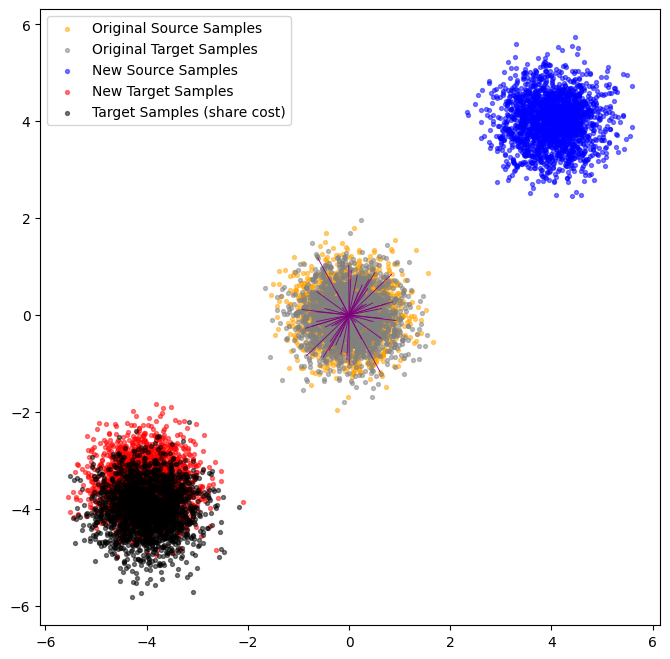

In [13]:
# import math
# theta = math.pi*2 / 3  # 60 degrees
# R = torch.tensor([[math.cos(theta), -math.sin(theta)],
#                   [math.sin(theta),  math.cos(theta)]], dtype=torch.float32)

# s1, s2 = 2.0, 0.5
# D = torch.diag(torch.tensor([s1, s2], dtype=torch.float32))

# A_coup = R @ D  # (2,2)
# b_shift = torch.tensor([-4.0, 0.0], dtype=torch.float32)  # (2,)
# b_shift_new = torch.tensor([-6.0, 1.0], dtype=torch.float32)

# def linear_coupling(n: int):
#     x = torch.randn(n, 2)
#     y = x @ A_coup.T + b_shift
#     return x, y

# def transport_map(x: torch.Tensor):
#     return x @ A_coup.T + b_shift

# class FunctionalDistribution:
#     def __init__(self, sampler_fn):
#         self.sampler_fn = sampler_fn
#     def sample(self, n):
#         return self.sampler_fn(n)

# coupling = FunctionalCouplingDistribution(linear_coupling)
# source, target = coupling.get_marginals()

# new_source = Simple2DGaussianDistribution(mean=torch.tensor([5.0, 5.0]), std=torch.tensor([0.25, 0.25]))

# m_prime = torch.tensor([5.0, 5.0], dtype=torch.float32)
# Sigma_mu_prime = (0.25 ** 2) * torch.eye(2, dtype=torch.float32)  # 0.0625 I

# mean_nu_prime = A_coup @ m_prime + b_shift_new
# cov_nu_prime  = A_coup @ Sigma_mu_prime @ A_coup.T
# mean_nu_prime = mean_nu_prime.detach()
# cov_nu_prime  = cov_nu_prime.detach()
# def sample_gaussian_with_cov(n: int, mean: torch.Tensor, cov: torch.Tensor):
#     mean = mean.cpu()
#     cov  = cov.cpu()
#     L = torch.linalg.cholesky(cov)
#     z = torch.randn(n, 2)          # CPU
#     return mean + z @ L.T          # CPU


# def nu_prime_sampler(n: int):
#     mean = mean_nu_prime
#     cov  = cov_nu_prime
#     return sample_gaussian_with_cov(n, mean, cov)

# def new_transport_map(x: torch.Tensor):
#     # Compute the new transport map with nu_prime's mean and covariance
#     mean = mean_nu_prime
#     cov  = cov_nu_prime
#     L = torch.linalg.cholesky(cov)
#     return x @ L.T + mean

# new_target = FunctionalDistribution(nu_prime_sampler)  # ✅ 用函数分布表示 nu'

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 8))
n_samples = 2000
coupling_samples = coupling.coupling_sample(n_samples)
source_samples = coupling_samples[0].cpu().numpy()
target_samples = coupling_samples[1].cpu().numpy()
new_source_samples = new_source.sample(n_samples).cpu().numpy()
new_target_samples = new_target.sample(n_samples).cpu().numpy()
# true_target_samples = new_source_samples @ A_coup.T.cpu().numpy() + b_shift.cpu().numpy()
non_perturbed_target_samples = Simple2DGaussianDistribution(mean=torch.tensor([-loc, -loc]), std=torch.tensor([0.5, 0.5])).sample(n_samples).cpu().numpy()

print(f"Mean of source samples in x dimension: {source_samples[:, 0].mean()}, Mean of source samples in y dimension: {source_samples[:, 1].mean()}")
print(f"Mean of target samples in x dimension: {target_samples[:, 0].mean()}, Mean of target samples in y dimension: {target_samples[:, 1].mean()}")
print(f"Mean of new source samples in x dimension: {new_source_samples[:, 0].mean()}, Mean of new source samples in y dimension: {new_source_samples[:, 1].mean()}")
print(f"Mean of new target samples in x dimension: {new_target_samples[:, 0].mean()}, Mean of new target samples in y dimension: {new_target_samples[:, 1].mean()}")

fig = plt.figure(figsize=(8, 8))
plt.scatter(source_samples[:, 0], source_samples[:, 1], c='orange', s=8, alpha=0.5, label='Original Source Samples')
plt.scatter(target_samples[:, 0], target_samples[:, 1], c='grey', s=8, alpha=0.5, label='Original Target Samples')
plt.scatter(new_source_samples[:, 0], new_source_samples[:, 1], c='blue', s=8, alpha=0.5, label='New Source Samples')
plt.scatter(new_target_samples[:, 0], new_target_samples[:, 1], c='red', s=8, alpha=0.5, label='New Target Samples')
plt.scatter(non_perturbed_target_samples[:, 0], non_perturbed_target_samples[:, 1], c='black', s=8, alpha=0.5, label='Target Samples (share cost)')
plt.plot([source_samples[:25, 0], target_samples[:25, 0]], [source_samples[:25, 1], target_samples[:25, 1]], c='purple', alpha=1.0, lw=0.6)
plt.legend()
plt.show()

In [14]:
class BidirectionalUnetStrategy(BidirectionalStrategy):
    # UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1, stop_middle=True).to(device)
    def _create_models(self, dim: int, hidden_size: int):
        wrapper = self.wrapper
        self.mu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.nu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.f_dual = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1, stop_middle=True))
        self.g_dual = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1, stop_middle=True))

        self.forward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.previous_forward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.backward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.previous_backward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))

        self.initial_mu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.initial_nu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.initial_forward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.initial_backward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))

In [15]:
training_config = TrainingConfig(
    device=device,
    iterations=25,
    dataset_size=500000,
    marginal_epochs=5000,
    pretrain_epochs=5000,
    dual_epochs = 100,
    cfm_epochs = 250,
    advance_steps=250,
    correction_epochs=2000,
    correction_each=0,
    l2_reg=0,
    lip_reg=0.0,
    mean_reg=0.0,
    sigma=0.25,
    sigma2=0.1,
    batch_size=batch_size,
    advance_with_flow=False,
    use_disk_coupling=True,
    coupling_save_dir='experiments/coupling_data',
    coupling_chunk_size=batch_size,
    loss='weighted',
    use_amp=False
)
small_training_config = TrainingConfig(
    device=device, iterations=200, batch_size=batch_size,
    dataset_size=1000,
    marginal_epochs=50, pretrain_epochs=50, dual_epochs=5, cfm_epochs=5,
    use_disk_coupling=True,
    coupling_save_dir='experiments/coupling_data',
    coupling_chunk_size=batch_size,
)
model_config = FeedForwardConfig(
    dimension=2,
    hidden_size=32,
    dual_learning_rate=1e-4,
    # flow_learning_rate=6e-4,
    # mu_learning_rate=6e-4,
    # nu_learning_rate=6e-4
)

flow_matching = ConditionalFlowMatching()
viz_config = VisualizeConfig(show_each=10, show_each_marginal=1000, show_each_pretrain=1000)
if use_image:
    strategy = BidirectionalUnetStrategy(unet_wrapper, model_config)
    visualizer = VisualizerImage(viz_config, img_shape=(1, 32, 32))
else:
    # strategy = BidirectionalStrategy(torch_wrapper, model_config)
    strategy = Strategy(torch_wrapper, model_config)
    visualizer = Visualizer(viz_config, transport_map=new_transport_map)

trainer = Trainer(
    coupling, new_source, new_target,
    flow_matching, strategy, visualizer,
    training_config, device
)

Using disk-based coupling distribution for memory efficiency.
Initializing disk coupling at experiments/coupling_data with 62 chunks...
Disk coupling initialized: 500000 samples in 62 chunks


In [ ]:
trainer.train(retrain=True, save='experiments/test_simple')#flip_perturbation2/')

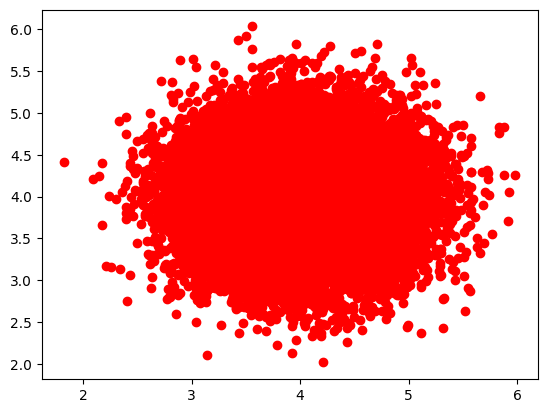

Mean of y in x dimension: -2.9072065353393555, Mean of y in y dimension: -3.631152391433716
Mean of y_target in x dimension: -3.9969727993011475, Mean of y in y dimension: -3.5013763904571533
Mean of y_coupling in x dimension: -2.9078259468078613, Mean of y in y dimension: -3.630258083343506
Mean of y_transport in x dimension: -4.003983974456787, Mean of y in y dimension: -3.4988393783569336)
Mean of y_transport_2 in x dimension: -4.000661849975586, Mean of y in y dimension: -3.5016250610351562)


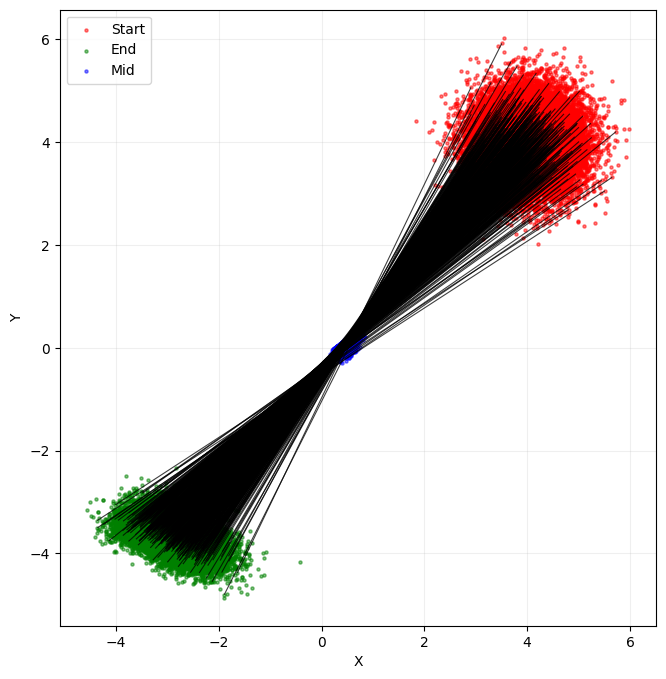

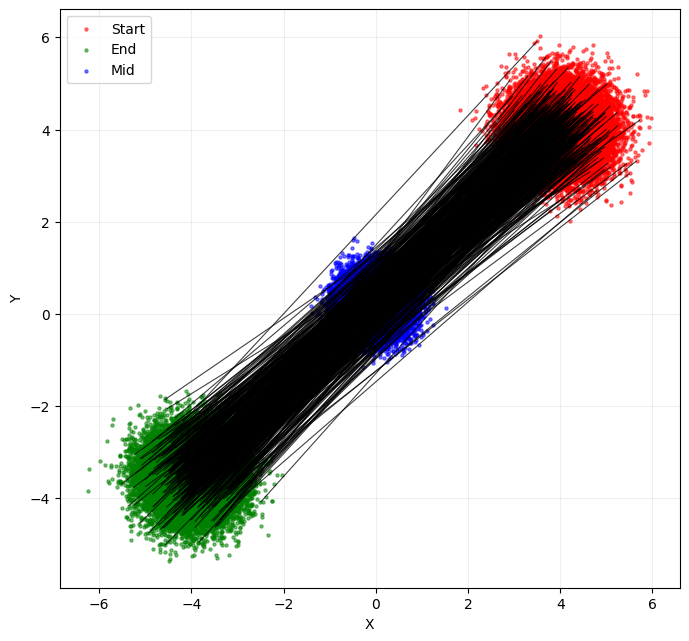

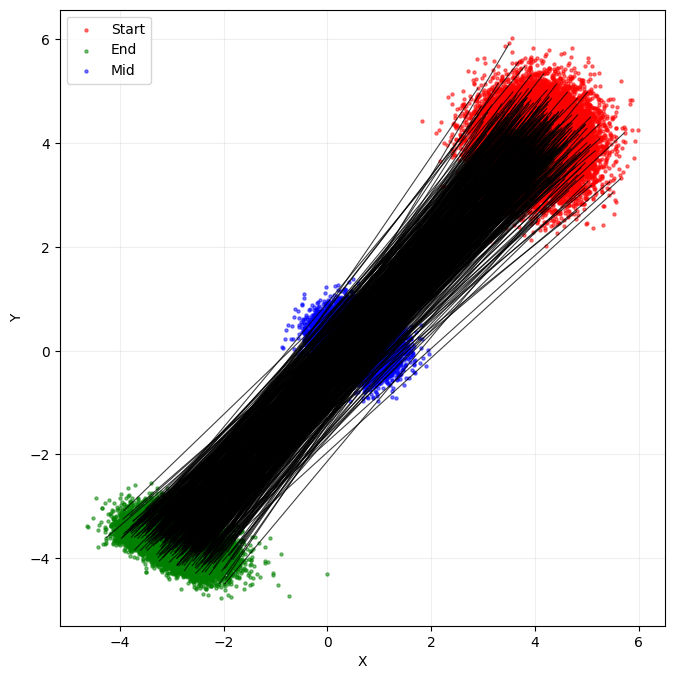

In [ ]:
import matplotlib.pyplot as plt
n_samples = 25000
x = new_source.sample(n_samples).to(trainer.device)
# x = trainer.current_coupling.sample_init(n_samples).to(trainer.device)
y = trainer.flow_matching.evolve(
    x,
    trainer.strategy.forward_model,
    num_steps=100,
    sigma=0.0,
    extend=True,
)[:, :2]

plt.scatter(x[:, 0].cpu(), x[:, 1].cpu(), color='red')
# plt.scatter(x_2[:, 0].cpu(), x_2[:, 1].cpu(), color='blue')
plt.show()

# Print mean of y in x and y dimensions
y_target = new_target.sample(n_samples).to(trainer.device)
_, y_coupling = trainer.current_coupling.coupling_sample(n_samples)
print(f"Mean of y in x dimension: {y[:, 0].mean().item()}, Mean of y in y dimension: {y[:, 1].mean().item()}")
print(f"Mean of y_target in x dimension: {y_target[:, 0].mean().item()}, Mean of y in y dimension: {y_target[:, 1].mean().item()}")
print(f"Mean of y_coupling in x dimension: {y_coupling[:, 0].mean().item()}, Mean of y in y dimension: {y_coupling[:, 1].mean().item()}")
y_transport = new_transport_map(new_source.sample(n_samples).cpu())
print(f"Mean of y_transport in x dimension: {y_transport[:, 0].mean().item()}, Mean of y in y dimension: {y_transport[:, 1].mean().item()})")
y_transport_2 = new_transport_map(x.cpu())
print(f"Mean of y_transport_2 in x dimension: {y_transport_2[:, 0].mean().item()}, Mean of y in y dimension: {y_transport_2[:, 1].mean().item()})")

trainer.visualizer._display_evolution(x.cpu(), y.cpu())
plt.show()
trainer.visualizer._display_evolution(x.cpu(), y_target.cpu())
plt.show()
trainer.visualizer._display_evolution(x.cpu(), y_coupling.cpu())
plt.show()

In [ ]:
# Save models in trainer.strategy
# trainer.strategy.forward_model
torch.save(trainer.strategy.forward_model.state_dict(), 'experiments/flip_perturbation2/final_forward_model.pth')
torch.save(trainer.strategy.backward_model.state_dict(), 'experiments/flip_perturbation2/final_backward_model.pth')

AttributeError: 'Strategy' object has no attribute 'backward_model'

In [ ]:
import matplotlib.pyplot as plt
n_samples = 6
x = trainer.new_source.sample(n_samples)
# y_target = x.flip(dims=[2])

angle = 10  # degrees
rotation = T.RandomRotation((angle, angle), fill=(-1,))
y_target = torch.flip(x, dims=[2])
y_target = rotation(y_target)

x, y_target = x.to(trainer.device), y_target.to(trainer.device)

x, y_target = trainer.current_coupling.coupling_sample(n_samples)
x, y_target = x.to(trainer.device), y_target.to(trainer.device)

y = trainer.flow_matching.evolve(
    x,
    trainer.strategy.forward_model,
    num_steps=25,
    sigma=0.0,
    extend=True,
)
y = y[:, :1, :, :]

y = torch.flip(x, dims=[2])
y = rotation(y)
trainer.visualizer._display_evolution(x.cpu(), y.cpu(), y_target.cpu())
plt.show()

# Print the average error between the evolved samples and the target
error = torch.mean(torch.abs(y - y_target))
print(f"Average error between evolved samples and target: {error.item()}")

initial_model = trainer.strategy.initial_forward_model
state_dict = torch.load('experiments/flip_perturbation2/initial_forward_model.pth', map_location=trainer.device)
initial_model.load_state_dict(state_dict)
n_samples = 6
y_init = trainer.flow_matching.evolve(
    x,
    initial_model,
    num_steps=25,
    sigma=0.0,
    extend=True,
)
y_init = y_init[:, :1, :, :]
trainer.visualizer._display_evolution(x.cpu(), y_init.cpu(), y_target.cpu())
plt.show()


error = torch.mean(torch.abs(y_init - y_target))
print(f"Average error between evolved samples and target: {error.item()}")

plt.figure(figsize=(12, 6))
for i in range(n_samples):
    plt.subplot(3, n_samples, i + 1)
    plt.imshow(y_target[i, 0].cpu() - y[i, 0].cpu(), cmap='gray')
    plt.title('Source')
    plt.axis('off')

    plt.subplot(3, n_samples, n_samples + i + 1)
    plt.imshow(y_target[i, 0].cpu() - y_init[i, 0].cpu(), cmap='gray')
    plt.title('Target - Evolved')
    plt.axis('off')

    plt.subplot(3, n_samples, 2 * n_samples + i + 1)
    plt.imshow(y[i, 0].cpu() - y_init[i, 0].cpu(), cmap='gray')
    plt.title('Target - Evolved')
    plt.axis('off')
plt.show()

# Print weights of the first layer of the forward model
first_layer_weights = trainer.strategy.forward_model.model.input_blocks[0][0].weight.data.cpu()
print("First layer weights of the forward model:")
print(first_layer_weights[:1])  # Print the weights of the first 5 filters

first_layer_weights = initial_model.model.input_blocks[0][0].weight.data.cpu()
print("First layer weights of the forward model:")
print(first_layer_weights[:1])  # Print the weights of the first 5 filters

# unet_wrapper(
#   (model): UNetModelWrapper(
#     (time_embed): Sequential(
#       (0): Linear(in_features=32, out_features=128, bias=True)
#       (1): SiLU()
#       (2): Linear(in_features=128, out_features=128, bias=True)
#     )
#     (input_blocks): ModuleList(
#       (0): TimestepEmbedSequential(
#         (0): Conv2d(2, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
#       )
#       (1): TimestepEmbedSequential(
#         (0): ResBlock(
#           (in_layers): Sequential(
#             (0): GroupNorm32(32, 32, eps=1e-05, affine=True)
#             (1): SiLU()
#             (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
#           )

IndexError: Dimension out of range (expected to be in range of [-2, 1], but got 2)

In [ ]:
import matplotlib.pyplot as plt
trainer.visualizer.display(10, trainer)
plt.show()

trainer.visualizer.display(11, trainer)
plt.show()